# Human vs. AI Text: Model B — Text Model + Style Model

Labels are 0 = Human and 1 = AI. Model B uses the **same stratified 2,000-passage validation set** as the baseline (`random_state=42`).

**Idea:** combine two simple models that look at different things.

| Part | Looks at | Model |
|---|---|---|
| Text model | *What* words and character patterns are used | Word + character TF-IDF → Logistic Regression (the baseline plus character n-grams) |
| Style model | *How* the passage is written: sentence length, punctuation, vocabulary richness | 12 style features → Gradient Boosting |
| Model B | Both | Weighted average of the two probabilities |

**Run order:** Select the project `.venv` kernel and run cells from top to bottom (about 5 minutes). The notebook finds `data/` from either the project root or `notebooks/`, and all generated files go to `outputs/`.

## Contents

1. [Environment and configuration](#1-environment-and-configuration)
2. [Load and clean the datasets](#2-load-and-clean-the-datasets)
3. [Reuse the training and validation split](#3-reuse-the-training-and-validation-split)
4. [Define the two models](#4-define-the-two-models)
5. [Tune hyperparameters](#5-tune-hyperparameters)
6. [Choose the blend weight](#6-choose-the-blend-weight)
7. [Train and evaluate](#7-train-and-evaluate)
8. [Save results and artifacts](#8-save-results-and-artifacts)
9. [Kaggle Submission](#9-kaggle-submission)

## 1. Environment and configuration

In [ ]:
%pip install pandas numpy matplotlib scikit-learn joblib

In [2]:
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

# Locate the project whether Jupyter starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "train.csv").is_file() and (folder / "data" / "test.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/train.csv and data/test.csv. "
                            "Start Jupyter from the project folder or its notebooks folder.")

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Load and clean the datasets

### 2.1 Why we normalize whitespace

Human passages in `train.csv` **never** contain a blank line, but many AI passages do. A model could learn "blank line ⇒ AI", which is a quirk of how the data was collected, not a real difference in writing. The test set also contains adversarially modified AI text, where formatting may be changed.

So we collapse all whitespace (line breaks, tabs, double spaces) into single spaces **in every passage** before modeling. The models then have to rely on the words and the writing itself.

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

for label, name in [(0, "Human"), (1, "AI")]:
    share = train.loc[train.label == label, "text"].str.contains("\n\n").mean()
    print(f"{name} passages containing a blank line: {share:.1%}")


def normalize_whitespace(texts):
    return texts.fillna("").str.replace(r"\s+", " ", regex=True).str.strip()


train["text"] = normalize_whitespace(train["text"])
test["text"] = normalize_whitespace(test["text"])
print("\nTraining shape:", train.shape, "| Test shape:", test.shape)

Human passages containing a blank line: 0.0%
AI passages containing a blank line: 66.0%



Training shape: (10000, 3) | Test shape: (3000, 2)


## 3. Reuse the training and validation split

Same settings as the baseline. If the baseline's `validation_ids.csv` exists, we confirm the split is identical.

In [4]:
train_idx, val_idx = train_test_split(
    np.arange(len(train)), test_size=2000, random_state=RANDOM_STATE, stratify=train["label"]
)
train_split, val_split = train.iloc[train_idx], train.iloc[val_idx]

ids_file = OUTPUT_DIR / "validation_ids.csv"
if ids_file.is_file():
    assert set(pd.read_csv(ids_file)["id"]) == set(val_split["id"]), "Split differs from the baseline!"
    print("Identical to the baseline split.")

X_train, y_train = train_split["text"], train_split["label"]
X_val, y_val = val_split["text"], val_split["label"]
print("Training examples:", len(X_train), "| Validation examples:", len(X_val))

Identical to the baseline split.
Training examples: 8000 | Validation examples: 2000


## 4. Define the two models

### 4.1 Text model: word + character TF-IDF → Logistic Regression

This is the baseline plus one addition. **Character n-grams** (3–5 letter chunks) capture spelling, punctuation and word endings that word features miss. `FeatureUnion` places the two TF-IDF matrices side by side.

In [5]:
def make_text_model(C=1.0):
    features = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=100000,
                                 sublinear_tf=True)),
    ])
    return Pipeline([
        ("tfidf", features),
        ("classifier", LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE)),
    ])


print(make_text_model())

Pipeline(steps=[('tfidf',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(max_features=50000,
                                                                 min_df=2,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True)),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 max_features=100000,
                                                                 min_df=3,
                                                                 ngram_range=(3,
                                                                              5),
                                          

### 4.2 Style model: 12 writing-style features → Gradient Boosting

Each feature describes *how* a passage is written, not which words it uses. Rates are per word so long and short passages are comparable.

| Feature | Intuition |
|---|---|
| `avg_word_len`, `avg_sent_len` | Word and sentence length. In our training data AI sentences average 33 words vs. 22 for humans |
| `sent_len_std` | Spread of sentence lengths. Higher for AI in absolute terms (12.8 vs. 10.8 words), but smaller relative to its longer average |
| `vocab_richness` | Unique words ÷ total words |
| punctuation rates | Commas, semicolons, `!`, `?`, quotes |
| `digit_rate`, `upper_rate` | Numbers and capitals (names, acronyms) |
| `lowercase_i` | A lowercase "i" is a casual habit: 3× more common in human passages |

Run the cell below to see the class averages for every feature.

Gradient boosting (many small decision trees) suits these features because they work in combination ("long sentences *and* few commas"), which a linear model can't capture.

In [6]:
def style_features(texts):
    texts = pd.Series(texts)
    words = texts.str.split()
    n_words = words.str.len().clip(lower=1)
    sent_lens = texts.str.split(r"(?<=[.!?])\s+").apply(lambda sents: [len(s.split()) for s in sents if s])

    return pd.DataFrame({
        "avg_word_len": texts.str.replace(" ", "").str.len() / n_words,
        "avg_sent_len": sent_lens.apply(np.mean),
        "sent_len_std": sent_lens.apply(np.std),
        "vocab_richness": words.apply(lambda w: len({x.lower() for x in w})) / n_words,
        "comma_rate": texts.str.count(",") / n_words,
        "semicolon_rate": texts.str.count(";") / n_words,
        "exclaim_rate": texts.str.count("!") / n_words,
        "question_rate": texts.str.count(r"\?") / n_words,
        "quote_rate": texts.str.count('"') / n_words,
        "digit_rate": texts.str.count(r"\d") / n_words,
        "upper_rate": texts.str.count(r"[A-Z]") / n_words,
        "lowercase_i": texts.str.count(r"\bi\b") / n_words,
    }).fillna(0)


def make_style_model(learning_rate=0.1, max_depth=None):
    return Pipeline([
        ("style", FunctionTransformer(style_features)),
        ("classifier", HistGradientBoostingClassifier(learning_rate=learning_rate, max_depth=max_depth,
                                                      random_state=RANDOM_STATE)),
    ])


# Compare average feature values for human (0) and AI (1) passages
style_features(X_train).groupby(y_train.values).mean().T.round(3)

,0,1
avg_word_len,4.965,5.165
avg_sent_len,22.420,33.181
sent_len_std,10.771,12.794
vocab_richness,0.633,0.661
comma_rate,0.047,0.046
semicolon_rate,0.002,0.001
exclaim_rate,0.000,0.002
question_rate,0.001,0.002
quote_rate,0.006,0.008
digit_rate,0.072,0.081


## 5. Tune hyperparameters

`GridSearchCV` tries each setting with 3-fold cross-validation **on the 8,000 training passages only**. The validation set isn't touched until Section 7.

In [7]:
search_results = []

text_search = GridSearchCV(make_text_model(), {"classifier__C": [1, 4, 10]}, cv=3, scoring="roc_auc", n_jobs=-1)
text_search.fit(X_train, y_train)

style_search = GridSearchCV(make_style_model(),
                            {"classifier__learning_rate": [0.05, 0.1], "classifier__max_depth": [3, None]},
                            cv=3, scoring="roc_auc", n_jobs=-1)
style_search.fit(X_train, y_train)

for name, search in [("Text model", text_search), ("Style model", style_search)]:
    table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "mean_fit_time"]]
    search_results.append(table.assign(model=name))
    print(f"{name}: best {search.best_params_}  (CV AUROC {search.best_score_:.4f})")

search_df = pd.concat(search_results)[["model", "params", "mean_test_score", "mean_fit_time"]]
display(search_df.round(4))

Text model: best {'classifier__C': 10}  (CV AUROC 0.9447)
Style model: best {'classifier__learning_rate': 0.1, 'classifier__max_depth': None}  (CV AUROC 0.8821)


,model,params,mean_test_score,mean_fit_time
0,Text model,{'classifier__C': 1},0.9400,8.6937
1,Text model,{'classifier__C': 4},0.9444,9.3467
2,Text model,{'classifier__C': 10},0.9447,8.7589
0,Style model,"{'classifier__learning_rate': 0.05, 'classifie...",0.8599,0.6215
1,Style model,"{'classifier__learning_rate': 0.05, 'classifie...",0.8808,0.7176
2,Style model,"{'classifier__learning_rate': 0.1, 'classifier...",0.8713,0.5995
3,Style model,"{'classifier__learning_rate': 0.1, 'classifier...",0.8821,0.6777


## 6. Choose the blend weight

Model B's probability = `w × style + (1 − w) × text`.

To pick `w` fairly, we use `cross_val_predict` to get **out-of-fold** predictions on the training passages. Each passage is predicted by a model that never saw it. Then we try `w` from 0 to 1.

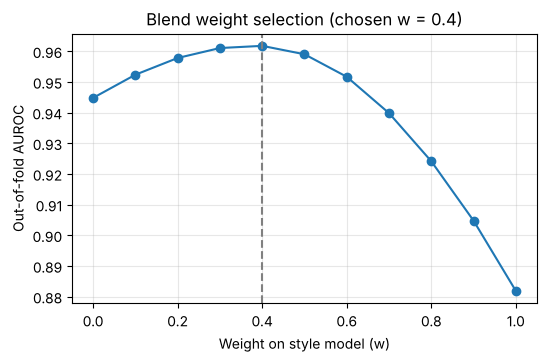

In [8]:
text_model = text_search.best_estimator_
style_model = style_search.best_estimator_

oof_text = cross_val_predict(text_model, X_train, y_train, cv=3, method="predict_proba", n_jobs=-1)[:, 1]
oof_style = cross_val_predict(style_model, X_train, y_train, cv=3, method="predict_proba", n_jobs=-1)[:, 1]

weights = np.round(np.arange(0, 1.01, 0.1), 1)
blend_auc = [roc_auc_score(y_train, w * oof_style + (1 - w) * oof_text) for w in weights]
STYLE_WEIGHT = weights[int(np.argmax(blend_auc))]

plt.figure(figsize=(6, 3.5))
plt.plot(weights, blend_auc, marker="o")
plt.axvline(STYLE_WEIGHT, color="gray", linestyle="--")
plt.xlabel("Weight on style model (w)"); plt.ylabel("Out-of-fold AUROC")
plt.title(f"Blend weight selection (chosen w = {STYLE_WEIGHT})"); plt.grid(alpha=0.3)
plt.show()

## 7. Train and evaluate

### 7.1 Fit on the 8,000 training passages and compare each development step

In [9]:
results = []

def record(name, model, train_probs, val_probs, seconds):
    results.append({"model": name, "train_auc": roc_auc_score(y_train, train_probs),
                    "val_auc": roc_auc_score(y_val, val_probs), "training_time_seconds": seconds})

# Step 0: the baseline, unchanged except for whitespace normalization
baseline = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
                     ("classifier", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))])

probs = {}
for name, model in [("Baseline: word TF-IDF + LR", baseline),
                    ("Text model: word + char TF-IDF + LR", text_model),
                    ("Style model: 12 features + Gradient Boosting", style_model)]:
    start = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - start
    probs[name] = (model.predict_proba(X_train)[:, 1], model.predict_proba(X_val)[:, 1])
    record(name, model, *probs[name], seconds)

# Model B: blend of the text and style models
text_tr, text_va = probs["Text model: word + char TF-IDF + LR"]
style_tr, style_va = probs["Style model: 12 features + Gradient Boosting"]
train_probs = STYLE_WEIGHT * style_tr + (1 - STYLE_WEIGHT) * text_tr
val_probs = STYLE_WEIGHT * style_va + (1 - STYLE_WEIGHT) * text_va
record(f"Model B: blend (w = {STYLE_WEIGHT})", None, train_probs, val_probs,
       results[1]["training_time_seconds"] + results[2]["training_time_seconds"])

comparison = pd.DataFrame(results)
comparison["auc_gap"] = comparison["train_auc"] - comparison["val_auc"]
display(comparison.round(4))

,model,train_auc,val_auc,training_time_seconds,auc_gap
0,Baseline: word TF-IDF + LR,0.9932,0.9361,3.3415,0.0571
1,Text model: word + char TF-IDF + LR,1.0000,0.9526,13.9659,0.0474
2,Style model: 12 features + Gradient Boosting,0.9658,0.8919,1.0359,0.0739
3,Model B: blend (w = 0.4),1.0000,0.9700,15.0018,0.0300


### 7.2 Model B: accuracy, ROC curve and confusion matrix (threshold 0.5)

Training AUROC: 1.0000 | Validation AUROC: 0.9700 | Gap: 0.0300 | Validation Accuracy: 0.9135


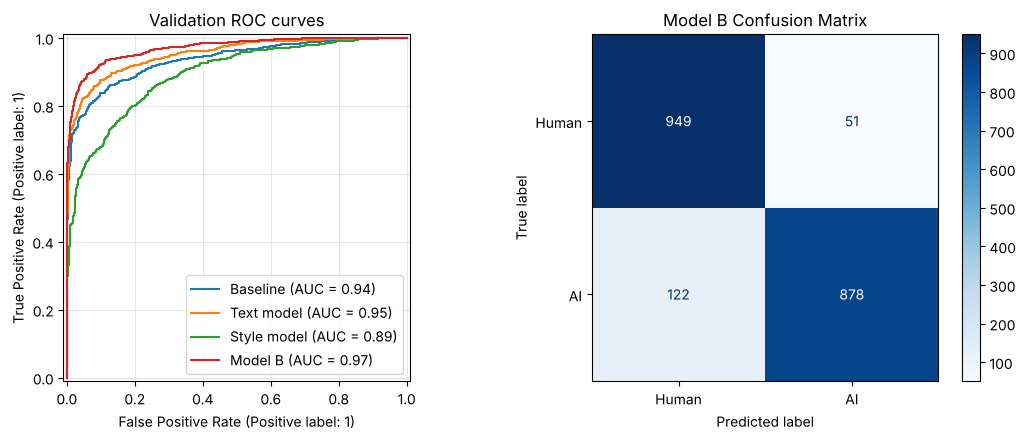

              precision    recall  f1-score   support

       Human       0.89      0.95      0.92      1000
          AI       0.95      0.88      0.91      1000

    accuracy                           0.91      2000
   macro avg       0.92      0.91      0.91      2000
weighted avg       0.92      0.91      0.91      2000



In [10]:
val_preds = (val_probs >= 0.5).astype(int)
train_auc, val_auc = roc_auc_score(y_train, train_probs), roc_auc_score(y_val, val_probs)
val_accuracy = accuracy_score(y_val, val_preds)
print(f"Training AUROC: {train_auc:.4f} | Validation AUROC: {val_auc:.4f} | "
      f"Gap: {train_auc - val_auc:.4f} | Validation Accuracy: {val_accuracy:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, (_, va) in probs.items():
    RocCurveDisplay.from_predictions(y_val, va, name=name.split(":")[0], ax=axes[0])
RocCurveDisplay.from_predictions(y_val, val_probs, name="Model B", ax=axes[0])
axes[0].set_title("Validation ROC curves"); axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay.from_predictions(y_val, val_preds, display_labels=["Human", "AI"], cmap="Blues", ax=axes[1])
axes[1].set_title("Model B Confusion Matrix")
plt.tight_layout(); plt.show()

print(classification_report(y_val, val_preds, target_names=["Human", "AI"]))

### 7.3 Which style features matter?

Permutation importance: shuffle one feature at a time on the validation set and measure how much AUROC drops. A bigger drop means a more important feature.

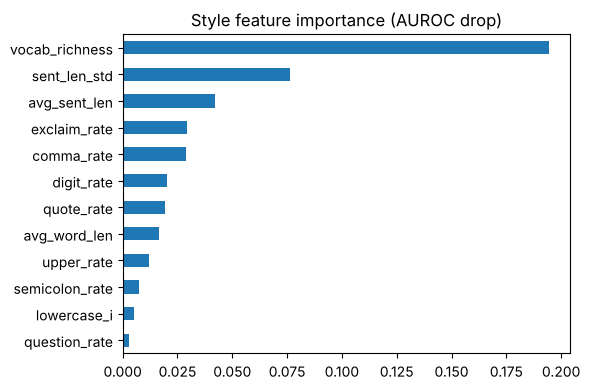

In [11]:
from sklearn.inspection import permutation_importance

F_val = style_features(X_val)
importance = permutation_importance(style_model.named_steps["classifier"], F_val, y_val,
                                    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
pd.Series(importance.importances_mean, index=F_val.columns).sort_values().plot.barh(
    figsize=(6, 4), title="Style feature importance (AUROC drop)")
plt.tight_layout(); plt.show()

## 8. Save results and artifacts

| File | Contents |
| --- | --- |
| `modelB_results.csv` | Development-step comparison (Section 7.1) |
| `modelB_hyperparameter_search.csv` | Grid search results (Section 5) |
| `modelB_validation_predictions.csv` | Validation IDs, text, labels and Model B predictions |
| `modelB_model.joblib` | Fitted text model, style model and blend weight |

In [12]:
comparison.to_csv(OUTPUT_DIR / "modelB_results.csv", index=False)
search_df.to_csv(OUTPUT_DIR / "modelB_hyperparameter_search.csv", index=False)

validation_predictions = val_split[["id", "text", "label"]].copy()
validation_predictions["predicted_probability"] = val_probs
validation_predictions["predicted_label"] = val_preds
validation_predictions.to_csv(OUTPUT_DIR / "modelB_validation_predictions.csv", index=False)

joblib.dump({"text_model": text_model, "style_model": style_model, "style_weight": STYLE_WEIGHT},
            OUTPUT_DIR / "modelB_model.joblib")
print("Saved Model B results to", OUTPUT_DIR.relative_to(PROJECT_ROOT))

Saved Model B results to outputs


## 9. Kaggle Submission

Retrain both models on all 10,000 labeled passages with the chosen settings, then blend their test predictions with the same weight.

In [13]:
from sklearn.base import clone

X_full, y_full = train["text"], train["label"]
start = time.perf_counter()
final_text = clone(text_model).fit(X_full, y_full)
final_style = clone(style_model).fit(X_full, y_full)
print(f"Retrained on {len(X_full)} passages in {time.perf_counter() - start:.1f} s")

test_probs = (STYLE_WEIGHT * final_style.predict_proba(test["text"])[:, 1]
              + (1 - STYLE_WEIGHT) * final_text.predict_proba(test["text"])[:, 1])

submission = pd.DataFrame({"id": test["id"], "label": test_probs})
submission.to_csv(OUTPUT_DIR / "submission_modelB.csv", index=False)
print("Submission saved to:", (OUTPUT_DIR / "submission_modelB.csv").relative_to(PROJECT_ROOT))
display(submission.head())

Retrained on 10000 passages in 17.4 s


Submission saved to: outputs/submission_modelB.csv


,id,label
0,13001,0.879019
1,13002,0.121563
2,13003,0.614808
3,13004,0.072934
4,13005,0.957590
